# What Travels? Final project analysis

This notebook replaces the original modeling workflow. Keep the supplied Excel workbook beside it and choose **Run All**. All source data remain unchanged; audited data, tables, figures, and model files are written to `results_final/`.

**Main outcome:** the first Power Four entry season. The original workbook selected a later qualifying season for three pitchers. The qualifying-season results are retained as descriptive sensitivity results. The sample still excludes transfers who never reached 10 Power Four innings by 2026.

**Evaluation status:** retrospective. The original 2026 results were already inspected. Nested cross-validation estimates the entire selection workflow; the chronological analysis is a separate, previously inspected cohort check. No new independent test cohort is available.

Runtime can be several minutes and depends on the computer. Defaults evaluate all 11 outcomes with ten repetitions of five outer folds and three inner folds. Primary paper outcomes are ERA, BB%, K%, and innings. These choices are retrospective and should be disclosed.


## Optional environment setup
Run the following cell only if your selected kernel lacks a dependency. Uncomment the installation line if needed.

In [1]:
# %pip install numpy pandas scipy scikit-learn openpyxl matplotlib joblib

## Imports and dependencies

In [2]:
"""What Travels? Reproducible final-paper analysis. Run from this folder."""
from pathlib import Path
import hashlib
import json
import platform
import importlib.metadata
import numpy as np
import pandas as pd
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt
from scipy.stats import spearmanr
from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Ridge, ElasticNet
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.model_selection import KFold, train_test_split
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import joblib



## Configuration

In [3]:
SEED = 6021
OUT = Path('results_final')
OUT.mkdir(exist_ok=True)
BOOTSTRAPS = 2000
OUTER_REPEATS = 10
WORKLOAD_THRESHOLDS = (10, 20)
TARGETS = ['ERA','WHIP','H/9','HR/9','BB/9','K/9','K/BB','K%','BB%','K-BB%','IP']
PRIMARY = ['ERA','BB%','K%','IP']
ALPHA = .20  # 80% split-conformal ranges, subject to exchangeability
plt.rcParams.update({'figure.dpi':140, 'axes.spines.top':False,
                     'axes.spines.right':False, 'font.size':10})

def save(df, name):
    df.to_csv(OUT / (name+'.csv'), index=False)
    return df

def innings_to_outs(values):
    """Convert baseball notation to outs; reject invalid fractional digits."""
    x = pd.to_numeric(values, errors='raise').astype(float)
    whole = np.floor(x)
    tenth = np.rint((x-whole)*10)
    bad = x.notna() & ((x<0) | ~tenth.isin([0,1,2]) |
                       (np.abs(x-(whole+tenth/10))>1e-7))
    if bad.any():
        raise ValueError(f'Invalid baseball innings: {x[bad].tolist()}')
    return whole*3+tenth


## Load, audit, and rebuild rates

In [4]:
def load_data(path):
    summary = pd.read_excel(path, sheet_name='Transfer Summary', header=4).dropna(how='all')
    raw = pd.read_excel(path, sheet_name='Player Seasons', header=4).dropna(how='all')
    assert not summary.Player.duplicated().any(), 'Duplicate names require manual resolution.'
    assert not raw.duplicated(['Player','Season','School']).any()
    assert not raw.groupby('Player')['Player ID'].nunique().gt(1).any()
    assert not raw.groupby('Player ID')['Player'].nunique().gt(1).any()
    d = raw.copy()
    converted = innings_to_outs(d.IP)
    assert np.allclose(converted, d.Outs, equal_nan=True), 'IP/Outs disagreement'
    d['IP_baseball'] = d.IP
    d['IP'] = d.Outs/3
    for c in ['G','GS','TBF','H','R','ER','HR','BB','HBP','SO','Outs']:
        v = d[c].dropna()
        assert (v>=0).all() and np.allclose(v,np.rint(v)), f'Invalid counts: {c}'
    assert (d.GS<=d.G).all() and (d.ER<=d.R).all() and (d.HR<=d.H).all()
    assert ((d.SO+d.BB+d.HBP)<=d.TBF).all()
    ip = d.IP.where(d.IP>0)
    tbf = d.TBF.where(d.TBF>0)
    formulas = {'ERA':9*d.ER/ip, 'WHIP':(d.H+d.BB)/ip,
        'H/9':9*d.H/ip,'HR/9':9*d.HR/ip,'BB/9':9*d.BB/ip,
        'K/9':9*d.SO/ip,'K/BB':d.SO/d.BB.where(d.BB>0),
        'K%':d.SO/tbf,'BB%':d.BB/tbf,'K-BB%':(d.SO-d.BB)/tbf,
        'Approx. Opp BA':d.H/(d.TBF-d.BB-d.HBP).where((d.TBF-d.BB-d.HBP)>0)}
    audit=[]
    for c, calculated in formulas.items():
        both = raw[c].notna() & calculated.notna()
        diff = (raw.loc[both,c]-calculated[both]).abs()
        audit.append({'check':c,'compared_rows':int(both.sum()),
                      'max_absolute_difference':float(diff.max()),
                      'mismatches_over_1e_6':int((diff>1e-6).sum())})
        assert (diff<=1e-6).all(), f'Rate mismatch: {c}'
        d[c]=calculated
    save(pd.DataFrame(audit),'rate_audit')
    missing = raw.isna().sum().rename_axis('column').reset_index(name='missing_rows')
    save(missing,'missing_data_audit')
    save(d,'clean_player_seasons')
    return summary,d

def make_pairs(summary, seasons, first_entry=True):
    rows=[]
    for _,r in summary.iterrows():
        a=seasons[(seasons.Player==r.Player)&(seasons.Season==r['Origin Season'])&
                  (seasons.School==r['Origin School'])]
        year=r['Transfer Cohort'] if first_entry else r['Power 4 Season']
        school=r['P4 Entry School'] if first_entry else r['Power 4 School']
        b=seasons[(seasons.Player==r.Player)&(seasons.Season==year)&(seasons.School==school)]
        assert len(a)==len(b)==1, f'Unmatched pair: {r.Player}'
        a,b=a.iloc[0],b.iloc[0]
        assert a['Player ID']==b['Player ID']
        assert a.Season<r['Transfer Cohort']<=b.Season
        row={'Player':r.Player,'Player ID':a['Player ID'],
             'cohort':int(r['Transfer Cohort']), 'source_year':int(a.Season),
             'outcome_year':int(b.Season), 'Origin School':a.School,
             'Destination School':b.School, 'Origin Conference':a.Conference,
             'Destination Conference':b.Conference, 'source_Class':a.Class,
             'year_gap':r['Transfer Cohort']-a.Season}
        for prefix,line in [('source_',a),('dest_',b)]:
            for c in TARGETS+['G','GS','TBF','H','R','ER','HR','BB','HBP','SO','Outs']:
                row[prefix+c]=line[c]
            row[prefix+'start_rate']=line.GS/line.G if line.G else np.nan
            row[prefix+'ip_per_game']=line.IP/line.G if line.G else np.nan
        rows.append(row)
    result=pd.DataFrame(rows)
    assert result['Player ID'].is_unique and len(result)==len(summary)
    return result


## Descriptive estimates and portability

In [5]:
def bootstrap_mean(x, seed=SEED):
    x=np.asarray(x,float); rng=np.random.default_rng(seed)
    means=x[rng.integers(0,len(x),(BOOTSTRAPS,len(x)))].mean(axis=1)
    return np.quantile(means,[.025,.975])

def describe(pairs, name):
    rows=[]
    for target in TARGETS:
        z=pairs[['source_'+target,'dest_'+target]].dropna().to_numpy(float)
        a,b=z.T; delta=b-a
        rng=np.random.default_rng(SEED); cor=[]
        for _ in range(BOOTSTRAPS):
            idx=rng.integers(0,len(a),len(a))
            if np.std(a[idx])>0 and np.std(b[idx])>0:
                cor.append(spearmanr(a[idx],b[idx]).statistic)
        lo,hi=bootstrap_mean(delta)
        rows.append({'target':target,'n':len(z),'source_mean':a.mean(),
             'destination_mean':b.mean(),'mean_change':delta.mean(),
             'change_low':lo,'change_high':hi,'median_change':np.median(delta),
             'pearson':np.corrcoef(a,b)[0,1],'spearman':spearmanr(a,b).statistic,
             'spearman_low':np.quantile(cor,.025),'spearman_high':np.quantile(cor,.975)})
    return save(pd.DataFrame(rows),name)


## Models and strictly training-only selection

In [6]:
# Small numeric feature sets avoid unstable conference dummy effects with n=70.
# Destination conference and future role are deliberately excluded from prediction.
def features(target, group):
    own=['source_'+target]
    role=['source_IP','source_start_rate','source_ip_per_game','year_gap']
    skill=['source_K%','source_BB%','source_HR/9','source_H/9','source_ERA']
    return list(dict.fromkeys(own+(role if group in ['role','full'] else [])+
                              (skill if group=='full' else [])))

def pipeline(cols, estimator):
    prep=ColumnTransformer([('numeric',make_pipeline(
        SimpleImputer(strategy='median'),StandardScaler()),cols)])
    return make_pipeline(prep,estimator)

def candidates():
    # Same candidates for every outcome. Primary comparisons are specified above.
    return ['mean','median','unchanged','average_change','ridge_own','ridge_role',
            'ridge_full_1','ridge_full_10','ridge_full_100','elastic_full',
            'forest_full','boost_full']

def model_spec(name,target):
    group='own' if name=='ridge_own' else 'role' if name=='ridge_role' else 'full'
    cols=features(target,group)
    if name.startswith('ridge'):
        strength=float(name.rsplit('_',1)[1]) if name.rsplit('_',1)[1].isdigit() else 10.
        est=Ridge(alpha=strength)
    elif name=='elastic_full':
        est=ElasticNet(alpha=.05,l1_ratio=.25,max_iter=50000)
    elif name=='forest_full':
        est=RandomForestRegressor(n_estimators=80,max_depth=3,min_samples_leaf=6,
                                  max_features=.8,random_state=SEED,n_jobs=1)
    else:
        est=GradientBoostingRegressor(n_estimators=60,max_depth=1,min_samples_leaf=6,
                                      learning_rate=.04,random_state=SEED)
    return pipeline(cols,est)

def fit_named(name,train,target):
    y=train['dest_'+target].to_numpy(float)
    if name=='mean':return {'kind':name,'value':float(y.mean())}
    if name=='median':return {'kind':name,'value':float(np.median(y))}
    if name=='unchanged':return {'kind':name,'value':0.}
    if name=='average_change':
        return {'kind':name,'value':float((train['dest_'+target]-train['source_'+target]).mean())}
    model=model_spec(name,target)
    model.fit(train,y)
    return model

def predict(model,test,target):
    if isinstance(model,dict):
        pred=np.repeat(model['value'],len(test)) if model['kind'] in ('mean','median') else (
            test['source_'+target].to_numpy(float)+model['value'])
    else:pred=model.predict(test)
    # Identical physical bounds for all models, selection and evaluation.
    lower=-1 if target=='K-BB%' else 0
    upper=1 if target in ['K%','BB%','K-BB%'] else np.inf
    return np.clip(pred,lower,upper)

def select(train,target,seed):
    folds=list(KFold(3,shuffle=True,random_state=seed).split(train))
    rows=[]
    for name in candidates():
        truth=[]; preds=[]
        for a,b in folds:
            fit=fit_named(name,train.iloc[a],target)
            truth.extend(train.iloc[b]['dest_'+target])
            preds.extend(predict(fit,train.iloc[b],target))
        rows.append({'model':name,'inner_mae':mean_absolute_error(truth,preds)})
    scores=pd.DataFrame(rows).sort_values('inner_mae',kind='stable')
    return scores.iloc[0]['model'],scores

def metrics(y,p):
    return {'mae':mean_absolute_error(y,p),'rmse':mean_squared_error(y,p)**.5,
            'r2':r2_score(y,p)}

def evaluate(data, repeats=OUTER_REPEATS, targets=TARGETS):
    records=[]; selections=[]
    for target in targets:
        use=data.dropna(subset=['source_'+target,'dest_'+target]).reset_index(drop=True)
        print(f'Nested validation: {target}, n={len(use)}',flush=True)
        for repeat in range(repeats):
            cv=KFold(5,shuffle=True,random_state=SEED+repeat)
            for fold,(a,b) in enumerate(cv.split(use)):
                tr,te=use.iloc[a],use.iloc[b]
                winner,scores=select(tr,target,SEED+repeat*10+fold)
                selections.append({'target':target,'repeat':repeat,'fold':fold,'winner':winner})
                names={'selected':winner,'mean':'mean','median':'median','unchanged':'unchanged',
                       'average_change':'average_change','ridge_own':'ridge_own',
                       'ridge_role':'ridge_role','ridge_full':'ridge_full_10'}
                for label,name in names.items():
                    pred=predict(fit_named(name,tr,target),te,target)
                    for (_,r),p in zip(te.iterrows(),pred):
                        records.append({'Player ID':r['Player ID'],'Player':r.Player,
                            'cohort':r.cohort,'target':target,'repeat':repeat,'fold':fold,
                            'model':label,'selected_name':name,'actual':r['dest_'+target],
                            'predicted':p,'absolute_error':abs(r['dest_'+target]-p)})
    return pd.DataFrame(records),pd.DataFrame(selections)

def summarize_predictions(preds):
    # Scores pooled within repeat, then averaged. Repeats are not independent people.
    detail=[]
    for (t,m,r),g in preds.groupby(['target','model','repeat']):
        detail.append({'target':t,'model':m,'repeat':r,**metrics(g.actual,g.predicted)})
    return pd.DataFrame(detail).groupby(['target','model'],as_index=False)[['mae','rmse','r2']].mean()

def compare_errors(preds, candidate='selected'):
    # Average each person's loss across repeats before bootstrapping people.
    loss=preds.groupby(['target','Player ID','model']).absolute_error.mean().unstack('model')
    rows=[]
    for target in loss.index.get_level_values('target').unique():
        z=loss.loc[target]
        for baseline in ['mean','median','unchanged','average_change','ridge_own']:
            delta=(z[baseline]-z[candidate]).dropna()
            lo,hi=bootstrap_mean(delta)
            base=z[baseline].mean()
            rows.append({'target':target,'candidate':candidate,'baseline':baseline,'n':len(delta),
                'mae_reduction':delta.mean(),'reduction_low':lo,'reduction_high':hi,
                'relative_reduction':delta.mean()/base if base else np.nan,
                'interval_interpretation':'Descriptive paired pitcher bootstrap; overlapping training sets; not a formal significance test'})
    return pd.DataFrame(rows)


## Time-based evaluation and split-conformal uncertainty

In [7]:
def chronological(data):
    train=data[(data.cohort<2026)&(data.outcome_year<2026)].copy()
    test=data[data.cohort==2026].copy()
    records=[]; intervals=[]; tuning=[]; interval_bundle={}
    for target in TARGETS:
        tr=train.dropna(subset=['source_'+target,'dest_'+target]).reset_index(drop=True)
        te=test.dropna(subset=['source_'+target,'dest_'+target]).reset_index(drop=True)
        winner,scores=select(tr,target,SEED)
        tuning.append(scores.assign(target=target,selected=scores.model.eq(winner)))
        for label,name in {'selected':winner,'mean':'mean','median':'median','unchanged':'unchanged',
                           'average_change':'average_change','ridge_own':'ridge_own'}.items():
            p=predict(fit_named(name,tr,target),te,target)
            for (_,r),v in zip(te.iterrows(),p):
                records.append({'Player ID':r['Player ID'],'Player':r.Player,'target':target,
                    'model':label,'selected_name':name,'repeat':0,'actual':r['dest_'+target],
                    'predicted':v,'absolute_error':abs(r['dest_'+target]-v)})
        # Separate proper-training/calibration split. Selection uses proper training only.
        proper,cal=train_test_split(tr,test_size=15,random_state=SEED)
        name,_=select(proper,target,SEED)
        fitted=fit_named(name,proper,target)
        residual=np.abs(cal['dest_'+target].to_numpy()-predict(fitted,cal,target))
        rank=int(np.ceil((len(cal)+1)*(1-ALPHA)))
        q=float(np.sort(residual)[rank-1]) if rank<=len(cal) else float('inf')
        center=predict(fitted,te,target)
        lower_bound=-1 if target=='K-BB%' else 0
        upper_bound=1 if target in ['K%','BB%','K-BB%'] else np.inf
        lo=np.maximum(center-q,lower_bound); hi=np.minimum(center+q,upper_bound)
        for (_,r),c,l,h in zip(te.iterrows(),center,lo,hi):
            intervals.append({'Player':r.Player,'target':target,'actual':r['dest_'+target],
                'interval_center':c,'low':l,'high':h,'covered':l<=r['dest_'+target]<=h,
                'width':h-l,'nominal_coverage':1-ALPHA,'calibration_n':len(cal)})
        interval_bundle[target]={'fitted':fitted,'q':q,'name':name,
            'proper_training_n':len(proper),'calibration_n':len(cal)}
    return pd.DataFrame(records),pd.DataFrame(intervals),pd.concat(tuning),interval_bundle


## Figures, sensitivity, and reusable predictions

In [8]:
def figures(desc,pairs,scores,intervals):
    fig,axes=plt.subplots(2,2,figsize=(9,6))
    for ax,t in zip(axes.flat,PRIMARY):
        r=desc.set_index('target').loc[t]; scale=100 if '%' in t else 1
        ax.errorbar([r.mean_change*scale],[0],
          xerr=[[max(0,(r.mean_change-r.change_low)*scale)],
                [max(0,(r.change_high-r.mean_change)*scale)]],fmt='o',color='#24476b',capsize=5)
        ax.axvline(0,color='gray',lw=1); ax.set_yticks([])
        ax.set_title(t); ax.set_xlabel('Mean paired change'+(' (percentage points)' if '%' in t else ''))
    fig.suptitle('First Power Four season minus selected mid-major season\n95% pitcher bootstrap intervals',fontsize=12)
    fig.tight_layout(); fig.savefig(OUT/'figure_1_changes.png',dpi=300); plt.close(fig)
    fig,axes=plt.subplots(1,3,figsize=(11,3.5))
    for ax,t in zip(axes,['BB%','K%','ERA']):
        scale=100 if '%' in t else 1
        ax.scatter(pairs['source_'+t]*scale,pairs['dest_'+t]*scale,c='#24476b',alpha=.7)
        ax.set(title=t,xlabel='Mid-major'+(' (%)' if '%' in t else ''),ylabel='First Power Four'+(' (%)' if '%' in t else ''))
    fig.tight_layout();fig.savefig(OUT/'figure_2_portability.png',dpi=300);plt.close(fig)
    fig,axes=plt.subplots(2,2,figsize=(10,7))
    for ax,t in zip(axes.flat,PRIMARY):
        s=scores[scores.target==t].set_index('model').loc[['mean','median','unchanged','average_change','ridge_own','selected']]
        scale=100 if '%' in t else 1
        ax.barh(['Mean','Median','Unchanged','Average change','Single-stat ridge','Nested selection'],s.mae*scale,color='#24476b')
        ax.invert_yaxis(); ax.set(title=t,xlabel='Nested CV MAE'+(' (percentage points)' if '%' in t else ''))
    fig.tight_layout();fig.savefig(OUT/'figure_3_validation.png',dpi=300);plt.close(fig)
    t='ERA';z=intervals[intervals.target==t].sort_values('interval_center').reset_index(drop=True)
    fig,ax=plt.subplots(figsize=(10,4))
    ax.vlines(np.arange(len(z)),z.low,z.high,color='#9db4c8',lw=2,label='80% split-conformal range')
    ax.scatter(np.arange(len(z)),z.interval_center,color='#24476b',label='Interval-model prediction')
    ax.scatter(np.arange(len(z)),z.actual,color='#c16a36',marker='x',label='Observed ERA')
    ax.set(xlabel='2026 pitchers ordered by prediction',ylabel='ERA',title='Previously inspected 2026 cohort: interval diagnostic')
    ax.legend(fontsize=8);fig.tight_layout();fig.savefig(OUT/'figure_4_intervals.png',dpi=300);plt.close(fig)

def project_pitchers(new_pitchers,bundle):
    """Input source_IP is true decimal innings, NOT baseball notation.
    source_K% and source_BB% are proportions. Models may select different columns.
    Interval centers come from separate calibration models, never the all-data refit.
    """
    out=new_pitchers.copy()
    required=set(sum([features(t,'full') for t in bundle['targets']],[]))
    missing=required-set(out.columns)
    if missing:raise ValueError(f'Missing features: {sorted(missing)}')
    for target,model in bundle['point_models'].items():
        out['projected_'+target]=predict(model,out,target)
        details=bundle['interval_models'][target]
        center=predict(details['fitted'],out,target)
        lower=-1 if target=='K-BB%' else 0
        upper=1 if target in ['K%','BB%','K-BB%'] else np.inf
        out['interval_center_'+target]=center
        out['low_'+target]=np.maximum(center-details['q'],lower)
        out['high_'+target]=np.minimum(center+details['q'],upper)
    return out

def main(data_path=None):
    if data_path is None:
        files=list(Path('.').glob('Mid_Major*.xlsx'))
        if len(files)!=1:raise ValueError('Keep exactly one Mid_Major*.xlsx beside the notebook or supply its path.')
        data_path=files[0]
    path=Path(data_path)
    summary,seasons=load_data(path)
    pairs=save(make_pairs(summary,seasons,True),'paired_first_entry')
    qualifying=save(make_pairs(summary,seasons,False),'paired_first_qualifying')
    shifted=summary[summary['Power 4 Season']!=summary['Transfer Cohort']]
    save(shifted,'delayed_qualifying_seasons')
    desc=describe(pairs,'first_entry_changes_portability')
    describe(qualifying,'qualifying_changes_portability')
    sample=pairs.groupby(['cohort','Origin Conference','Destination Conference']).size().reset_index(name='pitchers')
    save(sample,'sample_composition')
    predictions,selections=evaluate(pairs)
    save(predictions,'nested_cv_predictions');save(selections,'nested_selection_frequency_detail')
    scores=save(summarize_predictions(predictions),'nested_cv_metrics')
    comparisons=save(compare_errors(predictions),'nested_cv_paired_comparisons')
    save(compare_errors(predictions,'ridge_full'),'full_features_vs_benchmarks')
    timepred,intervals,tuning,interval_models=chronological(pairs)
    save(timepred,'chronological_2026_predictions')
    timescores=save(summarize_predictions(timepred),'chronological_2026_metrics')
    save(compare_errors(timepred),'chronological_2026_paired_comparisons')
    save(tuning,'chronological_training_selection')
    save(intervals,'chronological_interval_predictions')
    coverage=save(intervals.groupby('target',as_index=False).agg(
        n=('covered','size'),empirical_coverage=('covered','mean'),mean_width=('width','mean')),'interval_coverage')
    # Descriptive sensitivity only: avoid repeatedly selecting an attractive model.
    sensitivity=[]
    for threshold in [10,20,30]:
        z=pairs[(pairs.source_IP>=threshold)&(pairs.dest_IP>=threshold)]
        for t in PRIMARY:
            delta=(z['dest_'+t]-z['source_'+t]).dropna()
            lo,hi=bootstrap_mean(delta)
            sensitivity.append({'restriction':f'both seasons >= {threshold} IP','target':t,
                'n':len(delta),'mean_change':delta.mean(),'low':lo,'high':hi})
    for t in PRIMARY:
        delta=(pairs['dest_'+t]-pairs['source_'+t]).dropna().to_numpy()
        loo=(delta.sum()-delta)/(len(delta)-1)
        sensitivity.append({'restriction':'leave one pitcher out: range of means','target':t,
            'n':len(delta),'mean_change':delta.mean(),'low':loo.min(),'high':loo.max()})
    save(pd.DataFrame(sensitivity),'descriptive_sensitivity')
    figures(desc,pairs,scores,intervals)
    diagnostics = run_validation_diagnostics(pairs, predictions, selections)
    point_models={};final_selection=[]
    for t in TARGETS:
        z=pairs.dropna(subset=['source_'+t,'dest_'+t])
        name,table=select(z,t,SEED)
        point_models[t]=fit_named(name,z,t)
        final_selection.append({'target':t,'selected_model':name})
    save(pd.DataFrame(final_selection),'all_data_refit_selection')
    bundle={'targets':TARGETS,'point_models':point_models,'interval_models':interval_models,
        'outcome':'First Power Four entry season, conditional on original eventual-10-IP sample',
        'interval_level':1-ALPHA,'seed':SEED,'input_IP_units':'true decimal innings',
        'warning':'2026 was previously inspected. Calibration coverage needs exchangeability; cohort shift can invalidate it.'}
    joblib.dump(bundle,OUT/'pitcher_projection_bundle.joblib')
    # Empty input schema, no invented player projections.
    cols=['Player']+list(dict.fromkeys(sum([features(t,'full') for t in TARGETS],[])))
    save(pd.DataFrame(columns=cols),'new_pitcher_input_template')
    versions={p:importlib.metadata.version(p) for p in ['numpy','pandas','scipy','scikit-learn','matplotlib','joblib','openpyxl']}
    manifest={'seed':SEED,'pitchers':len(pairs),'season_rows':len(seasons),
        'cohorts':pairs.cohort.value_counts().sort_index().to_dict(),
        'delayed_qualifying_pairs':len(shifted),'primary_outcomes':PRIMARY,
        'outer_repeats':OUTER_REPEATS,'outer_folds':5,'inner_folds':3,
        'predictive_workload_thresholds':list(WORKLOAD_THRESHOLDS),
        'bootstrap_resamples':BOOTSTRAPS,'python':platform.python_version(),
        'packages':versions,'input_sha256':hashlib.sha256(path.read_bytes()).hexdigest(),
        'evaluation_status':'Retrospective analysis; 2026 previously inspected',
        'selection_bias':'Original sample excludes transfers never reaching 10 Power Four innings by 2026.'}
    (OUT/'run_manifest.json').write_text(json.dumps(manifest,indent=2))
    lines=['# Results to review for the paper','',
      'These are generated findings, not a prewritten conclusion. Primary outcomes were chosen after the original abstract; this is retrospective analysis.',
      '',f'Sample: {len(pairs)} pitchers; {len(seasons)} player-season rows. {len(shifted)} original pairs used a later qualifying season.',
      'The main analysis now predicts the entry season, including entry seasons below 10 IP. The overall sample still conditions on eventual qualification.',
      '', '## First-entry paired changes (95% bootstrap intervals)']
    for _,r in desc[desc.target.isin(PRIMARY)].iterrows():
        lines.append(f'- {r.target}: mean change {r.mean_change:.4f} [{r.change_low:.4f}, {r.change_high:.4f}], Spearman {r.spearman:.3f} [{r.spearman_low:.3f}, {r.spearman_high:.3f}].')
    lines+=['','## Nested validation: selected workflow versus training median',
      'Positive reduction favors the selected workflow. Bootstrap intervals describe paired person-level losses and do not capture all model-training uncertainty.']
    for _,r in comparisons[(comparisons.baseline=='median')&comparisons.target.isin(PRIMARY)].iterrows():
        lines.append(f'- {r.target}: MAE reduction {r.mae_reduction:.4f} [{r.reduction_low:.4f}, {r.reduction_high:.4f}], relative reduction {r.relative_reduction:.1%}.')
    lines += diagnostic_findings(diagnostics, scores, timescores, coverage)
    lines+=['','## Interpretation rules',
      '- Compare all five benchmarks before claiming added value. A selected benchmark is a valid outcome.',
      '- Do not interpret intervals crossing zero as proof of no difference.',
      '- An average shift is not a causal transfer effect. Correlation is not individual prediction accuracy.',
      '- Report the 2026 chronological results separately and disclose prior inspection.',
      '- Rate projections from different models need not reconcile algebraically. Do not combine them into a synthetic stat line.',
      '- No all-transfer success classifier or NIL valuation is supported by this selected sample.',
      '- Verify source provenance and season completeness independently before submission; no external source data were added in this revision.']
    (OUT/'paper_findings.md').write_text('\n'.join(lines)+'\n')
    print('\nCompleted. Read results_final/paper_findings.md and run_manifest.json.',flush=True)
    return {'pairs':pairs,'changes':desc,'nested_metrics':scores,
            'chronological_metrics':timescores,'coverage':coverage,'bundle':bundle,
            **diagnostics}


## Robustness and feature comparisons

Workload sensitivity refits the same workflow after requiring at least 10 or 20 first-year Power Four innings. Both training and test rows are restricted to the stated population. These are retrospective outcome-defined subsets and cannot be used to screen recruits. Sample sizes, benchmarks and within-subset paired gains are reported for each threshold.

The workload feature comparison uses the same outer splits and fixed ridge penalty for all three feature sets. Positive paired differences favor the added features. Split variability describes repeat-to-repeat changes, and bootstrap intervals describe paired pitcher losses. Neither makes the repeated predictions independent.


In [9]:
def run_validation_diagnostics(pairs, predictions, selections):
    keys = ['target', 'repeat', 'fold', 'Player ID']
    assert not predictions.duplicated(keys + ['model']).any()
    repeat_counts = predictions.groupby(['target', 'Player ID', 'model']).repeat.nunique()
    assert repeat_counts.eq(OUTER_REPEATS).all()

    stability = selections.groupby(['target', 'winner']).size().unstack(fill_value=0)
    stability = stability.reindex(columns=candidates(), fill_value=0)
    stability = stability.stack().rename('folds').reset_index()
    stability['share'] = stability.folds / (5 * OUTER_REPEATS)
    assert stability.groupby('target').folds.sum().eq(5 * OUTER_REPEATS).all()
    save(stability, 'model_selection_stability')

    repeat_mae = predictions.groupby(['target', 'model', 'repeat'], as_index=False).absolute_error.mean()
    save(repeat_mae, 'nested_mae_by_repeat')
    repeat_stability = save(repeat_mae.groupby(['target', 'model'], as_index=False).agg(
        mean_mae=('absolute_error','mean'), sd_mae=('absolute_error','std'),
        min_mae=('absolute_error','min'), max_mae=('absolute_error','max')),
        'nested_repeat_stability')

    workload = predictions.query("target == 'IP'")
    errors = workload.pivot(index=keys, columns='model', values='absolute_error')
    gains, fold_rows = [], []
    for baseline, candidate in [('ridge_own','ridge_role'), ('ridge_role','ridge_full'),
                                 ('ridge_own','ridge_full')]:
        delta = errors[baseline] - errors[candidate]
        by_pitcher = delta.groupby('Player ID').mean()
        by_fold = delta.groupby(['repeat','fold']).mean()
        lo, hi = bootstrap_mean(by_pitcher)
        gains.append(dict(baseline=baseline, candidate=candidate, n=len(by_pitcher),
                          mae_reduction=by_pitcher.mean(), reduction_low=lo,
                          reduction_high=hi, folds_improved=int(by_fold.gt(0).sum()),
                          total_folds=len(by_fold)))
        fold_rows.append(by_fold.rename('mae_reduction').reset_index().assign(
            baseline=baseline, candidate=candidate))
    gains = save(pd.DataFrame(gains), 'workload_feature_gains')
    save(pd.concat(fold_rows, ignore_index=True), 'workload_feature_gains_by_fold')

    subsets = [(0, predictions[predictions.target.isin(PRIMARY)])]
    for threshold in WORKLOAD_THRESHOLDS:
        eligible = pairs[pairs.dest_IP.ge(threshold)]
        print(f'Predictive sensitivity: entry IP >= {threshold}; {len(eligible)} pitchers', flush=True)
        subset_predictions, _ = evaluate(eligible, targets=PRIMARY)
        subsets.append((threshold, subset_predictions))
    sensitivity_scores, sensitivity_gains = [], []
    for threshold, records in subsets:
        counts = records.groupby('target')['Player ID'].nunique().rename('n')
        sensitivity_scores.append(summarize_predictions(records).join(counts, on='target').assign(
            minimum_entry_ip=threshold))
        sensitivity_gains.append(compare_errors(records).assign(minimum_entry_ip=threshold))
    sensitivity_scores = save(pd.concat(sensitivity_scores, ignore_index=True),
                              'predictive_workload_sensitivity')
    sensitivity_gains = save(pd.concat(sensitivity_gains, ignore_index=True),
                             'predictive_workload_sensitivity_paired')
    save(pd.concat([p.assign(minimum_entry_ip=t) for t,p in subsets], ignore_index=True),
         'predictive_workload_sensitivity_predictions')

    fig, axes = plt.subplots(2, 2, figsize=(9, 6))
    for ax, target in zip(axes.flat, PRIMARY):
        scale = 100 if '%' in target else 1
        for model, label in [('median','Training median'), ('selected','Nested selection'),
                             ('ridge_own','Single-stat ridge')]:
            data = sensitivity_scores.query('target == @target and model == @model')
            ax.plot(data.minimum_entry_ip, scale*data.mae, marker='o', label=label)
        ax.set_title(target)
        ax.set_xticks([0, *WORKLOAD_THRESHOLDS], ['All', *map(str,WORKLOAD_THRESHOLDS)])
        ax.set_xlabel('Minimum first-year innings')
        ax.set_ylabel('MAE (percentage points)' if scale==100 else 'MAE')
    axes.flat[0].legend(fontsize=8)
    fig.suptitle('Predictive sensitivity across first-year workload subsets')
    fig.tight_layout()
    fig.savefig(OUT/'figure_5_workload_sensitivity.png',dpi=300)
    plt.close(fig)
    return dict(selection_stability=stability, repeat_stability=repeat_stability,
                workload_feature_gains=gains, predictive_sensitivity=sensitivity_scores)


def diagnostic_findings(diagnostics, scores, timescores, coverage):
    lines = ['', '## Benchmark comparisons and robustness']
    for label, metrics_table in [('Nested CV',scores), ('2026 chronological check',timescores)]:
        for target in PRIMARY:
            z = metrics_table.query('target == @target').set_index('model').mae
            scale = 100 if '%' in target else 1
            unit = ' percentage points' if scale==100 else (' innings' if target=='IP' else ' ERA units')
            lines.append(f'- {label}, {target} MAE: selected {z.selected*scale:.2f}, '
                         f'training median {z["median"]*scale:.2f}, single-stat ridge '
                         f'{z.ridge_own*scale:.2f}{unit}.')
    for r in diagnostics['workload_feature_gains'].itertuples(index=False):
        lines.append(f'- Workload, {r.baseline} to {r.candidate}: paired MAE reduction '
                     f'{r.mae_reduction:.2f} innings [{r.reduction_low:.2f}, {r.reduction_high:.2f}], '
                     f'improvement in {r.folds_improved}/{r.total_folds} outer folds.')
    for threshold in WORKLOAD_THRESHOLDS:
        z = diagnostics['predictive_sensitivity'].query('minimum_entry_ip == @threshold')
        for target in PRIMARY:
            rows = z.query('target == @target').set_index('model')
            scale = 100 if '%' in target else 1
            unit = 'percentage points' if scale==100 else ('innings' if target=='IP' else 'ERA units')
            lines.append(f'- Entry workload ≥{threshold} IP, {target} (n={rows.loc["selected","n"]}): '
                         f'selected MAE {rows.loc["selected","mae"]*scale:.2f} vs training median '
                         f'{rows.loc["median","mae"]*scale:.2f} {unit}.')
    lines += ['', 'Workload thresholds define different retrospective populations. Compare models '
              'within each threshold. Selection frequencies and repeat variation are recorded '
              'in model_selection_stability.csv and nested_repeat_stability.csv.']
    return lines


## Run the full analysis
Set `data_path` explicitly below if your workbook has a different name. The final point models use all available paired pitchers and must not be evaluated as independent tests.

In [10]:
results = main()


Nested validation: ERA, n=70
Nested validation: WHIP, n=70
Nested validation: H/9, n=70
Nested validation: HR/9, n=70
Nested validation: BB/9, n=70
Nested validation: K/9, n=70
Nested validation: K/BB, n=69
Nested validation: K%, n=70
Nested validation: BB%, n=70
Nested validation: K-BB%, n=70
Nested validation: IP, n=70
Predictive sensitivity: entry IP >= 10; 67 pitchers
Nested validation: ERA, n=67
Nested validation: BB%, n=67
Nested validation: K%, n=67
Nested validation: IP, n=67
Predictive sensitivity: entry IP >= 20; 53 pitchers
Nested validation: ERA, n=53
Nested validation: BB%, n=53
Nested validation: K%, n=53
Nested validation: IP, n=53

Completed. Read results_final/paper_findings.md and run_manifest.json.


## Review the main paper outputs

# Results to review for the paper

These are generated findings, not a prewritten conclusion. Primary outcomes were chosen after the original abstract; this is retrospective analysis.

Sample: 70 pitchers; 241 player-season rows. 3 original pairs used a later qualifying season.
The main analysis now predicts the entry season, including entry seasons below 10 IP. The overall sample still conditions on eventual qualification.

## First-entry paired changes (95% bootstrap intervals)
- ERA: mean change 0.7165 [-0.0216, 1.5602], Spearman 0.256 [0.021, 0.453].
- K%: mean change 0.0008 [-0.0189, 0.0231], Spearman 0.209 [-0.033, 0.438].
- BB%: mean change 0.0092 [-0.0021, 0.0210], Spearman 0.404 [0.158, 0.615].
- IP: mean change -21.7476 [-26.9530, -16.3080], Spearman 0.374 [0.161, 0.575].

## Nested validation: selected workflow versus training median
Positive reduction favors the selected workflow. Bootstrap intervals describe paired person-level losses and do not capture all model-training uncertainty.
- BB%: MAE reduction 0.0010 [-0.0024, 0.0042], relative reduction 2.9%.
- ERA: MAE reduction -0.0280 [-0.1400, 0.0571], relative reduction -1.6%.
- IP: MAE reduction 1.8105 [-0.7487, 4.3149], relative reduction 11.1%.
- K%: MAE reduction -0.0016 [-0.0037, 0.0007], relative reduction -2.9%.

## Benchmark comparisons and robustness
- Nested CV, ERA MAE: selected 1.74, training median 1.71, single-stat ridge 1.75 ERA units.
- Nested CV, BB% MAE: selected 3.35, training median 3.45, single-stat ridge 3.19 percentage points.
- Nested CV, K% MAE: selected 5.55, training median 5.39, single-stat ridge 5.39 percentage points.
- Nested CV, IP MAE: selected 14.49, training median 16.30, single-stat ridge 15.87 innings.
- 2026 chronological check, ERA MAE: selected 1.32, training median 1.32, single-stat ridge 1.35 ERA units.
- 2026 chronological check, BB% MAE: selected 2.26, training median 2.77, single-stat ridge 1.87 percentage points.
- 2026 chronological check, K% MAE: selected 3.59, training median 3.59, single-stat ridge 3.60 percentage points.
- 2026 chronological check, IP MAE: selected 12.09, training median 12.75, single-stat ridge 13.80 innings.
- Workload, ridge_own to ridge_role: paired MAE reduction 0.95 innings [-0.11, 2.07], improvement in 41/50 outer folds.
- Workload, ridge_role to ridge_full: paired MAE reduction 1.11 innings [0.08, 2.19], improvement in 41/50 outer folds.
- Workload, ridge_own to ridge_full: paired MAE reduction 2.06 innings [0.64, 3.50], improvement in 43/50 outer folds.
- Entry workload ≥10 IP, ERA (n=67): selected MAE 1.28 vs training median 1.29 ERA units.
- Entry workload ≥10 IP, BB% (n=67): selected MAE 2.88 vs training median 3.01 percentage points.
- Entry workload ≥10 IP, K% (n=67): selected MAE 4.79 vs training median 4.74 percentage points.
- Entry workload ≥10 IP, IP (n=67): selected MAE 15.10 vs training median 15.52 innings.
- Entry workload ≥20 IP, ERA (n=53): selected MAE 1.02 vs training median 0.99 ERA units.
- Entry workload ≥20 IP, BB% (n=53): selected MAE 2.49 vs training median 2.51 percentage points.
- Entry workload ≥20 IP, K% (n=53): selected MAE 4.57 vs training median 4.35 percentage points.
- Entry workload ≥20 IP, IP (n=53): selected MAE 13.98 vs training median 14.14 innings.

Workload thresholds define different retrospective populations. Compare models within each threshold. Selection frequencies and repeat variation are recorded in model_selection_stability.csv and nested_repeat_stability.csv.

## Interpretation rules
- Compare all five benchmarks before claiming added value. A selected benchmark is a valid outcome.
- Do not interpret intervals crossing zero as proof of no difference.
- An average shift is not a causal transfer effect. Correlation is not individual prediction accuracy.
- Report the 2026 chronological results separately and disclose prior inspection.
- Rate projections from different models need not reconcile algebraically. Do not combine them into a synthetic stat line.
- No all-transfer success classifier or NIL valuation is supported by this selected sample.
- Verify source provenance and season completeness independently before submission; no external source data were added in this revision.


,target,model,mae,rmse,r2
0,BB%,average_change,0.0355,0.0521,-0.0079
1,BB%,mean,0.0345,0.0526,-0.0290
2,BB%,median,0.0345,0.0527,-0.0320
3,BB%,ridge_full,0.0345,0.0520,-0.0054
4,BB%,ridge_own,0.0319,0.0502,0.0632
5,BB%,ridge_role,0.0327,0.0507,0.0428
6,BB%,selected,0.0335,0.0512,0.0229
7,BB%,unchanged,0.0359,0.0519,-0.0019
16,ERA,average_change,2.0005,3.4667,-0.1980
17,ERA,mean,1.7445,3.2262,-0.0376


,target,model,mae,rmse,r2
0,BB%,average_change,0.0257,0.0348,-0.5843
1,BB%,mean,0.0225,0.0293,-0.1247
2,BB%,median,0.0277,0.0343,-0.5411
3,BB%,ridge_own,0.0187,0.0278,-0.0073
4,BB%,selected,0.0226,0.0293,-0.1227
5,BB%,unchanged,0.0281,0.0372,-0.8113
12,ERA,average_change,1.8028,2.4542,-0.9054
13,ERA,mean,1.3428,1.8290,-0.0582
14,ERA,median,1.3166,1.9076,-0.1511
15,ERA,ridge_own,1.3471,1.8037,-0.0292


,target,n,empirical_coverage,mean_width
0,BB%,20,1.00,0.210
1,BB/9,20,0.95,7.015
2,ERA,20,0.90,6.688
3,H/9,20,0.95,8.498
4,HR/9,20,0.90,2.365
5,IP,20,0.85,52.701
6,K%,20,0.95,0.214
7,K-BB%,20,1.00,0.346
8,K/9,20,1.00,10.947
9,K/BB,20,1.00,6.166


,baseline,candidate,n,mae_reduction,reduction_low,reduction_high,folds_improved,total_folds
0,ridge_own,ridge_role,70,0.950,-0.109,2.073,41,50
1,ridge_role,ridge_full,70,1.113,0.085,2.191,41,50
2,ridge_own,ridge_full,70,2.063,0.638,3.504,43,50


,target,model,mae,rmse,r2,n,minimum_entry_ip
2,BB%,median,0.0345,0.0527,-0.0320,70,0
6,BB%,selected,0.0335,0.0512,0.0229,70,0
10,ERA,median,1.7070,3.2371,-0.0446,70,0
14,ERA,selected,1.7350,3.1933,-0.0197,70,0
18,IP,median,16.2995,21.4241,-0.0659,70,0
22,IP,selected,14.4890,18.2879,0.2216,70,0
26,K%,median,0.0539,0.0797,-0.0351,70,0
30,K%,selected,0.0555,0.0820,-0.0957,70,0
34,BB%,median,0.0301,0.0407,-0.0401,67,10
38,BB%,selected,0.0288,0.0398,0.0081,67,10


,target,winner,folds,share
0,BB%,mean,2,0.04
1,BB%,median,1,0.02
4,BB%,ridge_own,29,0.58
5,BB%,ridge_role,7,0.14
8,BB%,ridge_full_100,8,0.16
10,BB%,forest_full,3,0.06
24,ERA,mean,3,0.06
25,ERA,median,28,0.56
28,ERA,ridge_own,1,0.02
29,ERA,ridge_role,11,0.22


,target,model,mean_mae,sd_mae,min_mae,max_mae
2,BB%,median,0.0345,0.0003,0.0341,0.0350
6,BB%,selected,0.0335,0.0015,0.0310,0.0365
18,ERA,median,1.7070,0.0317,1.6717,1.7596
22,ERA,selected,1.7350,0.0698,1.6417,1.8264
42,IP,median,16.2995,0.4328,15.8762,16.9857
46,IP,selected,14.4890,1.0040,13.3158,16.2318
50,K%,median,0.0539,0.0008,0.0532,0.0554
54,K%,selected,0.0555,0.0027,0.0528,0.0604


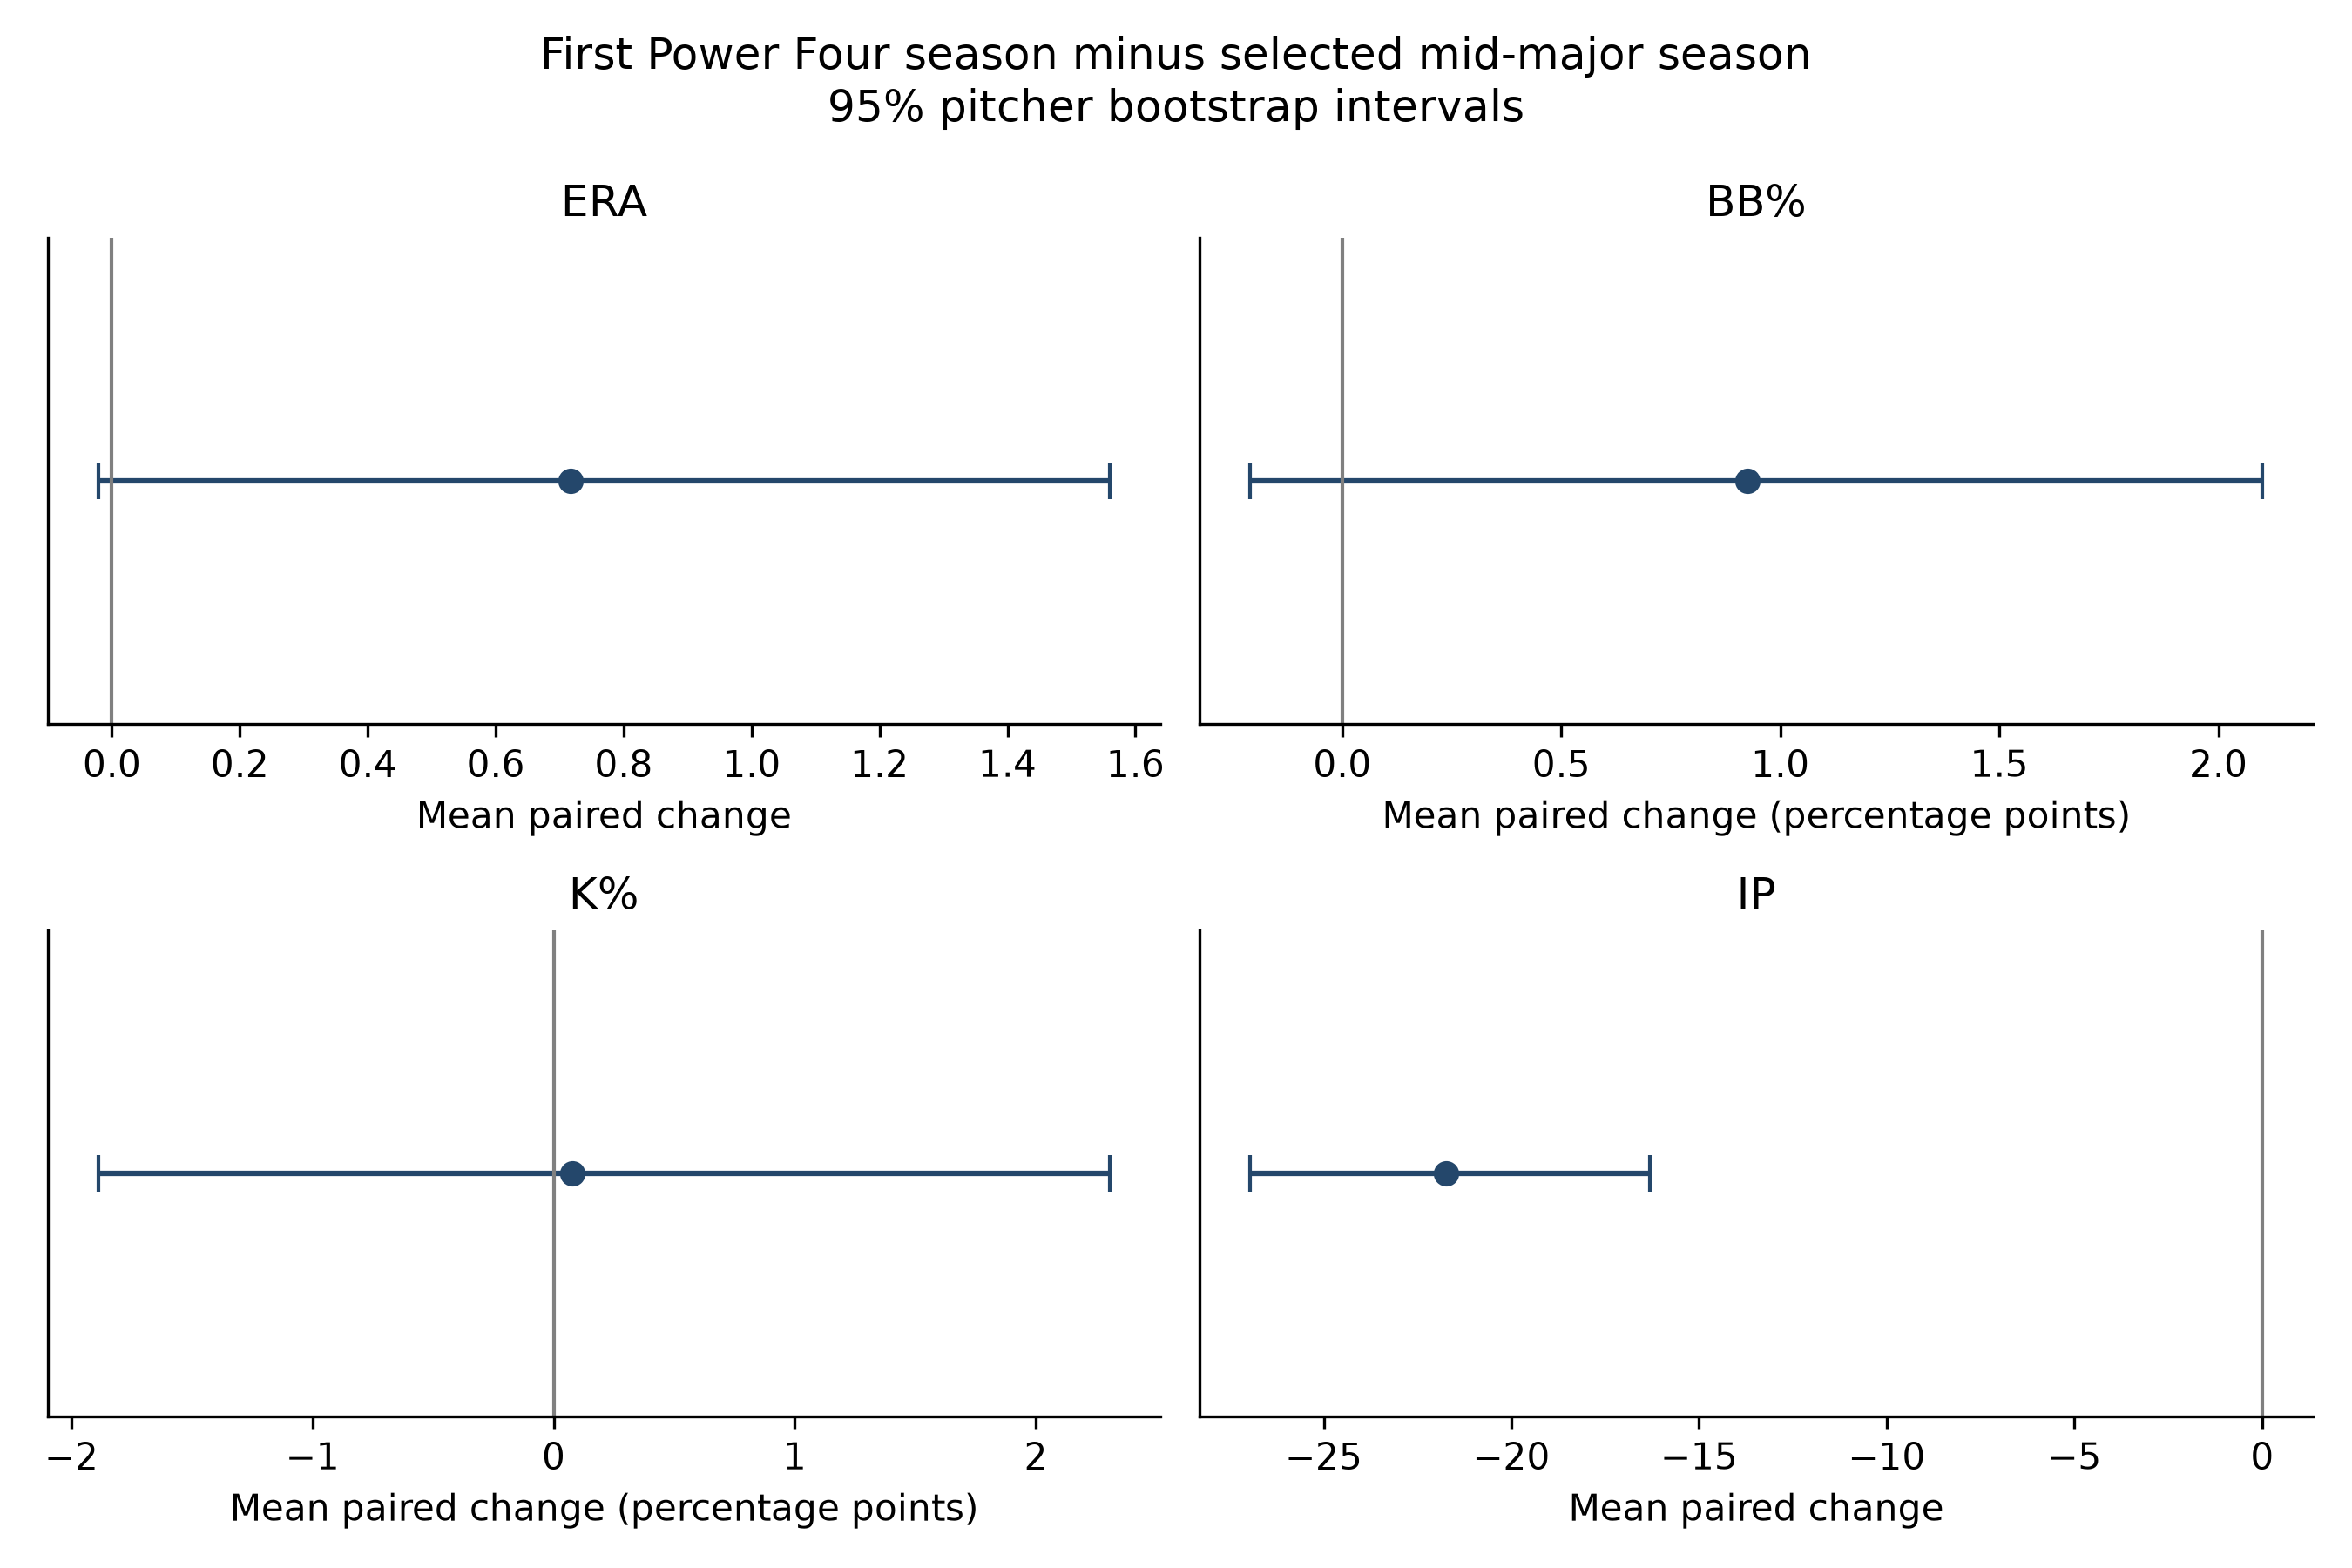

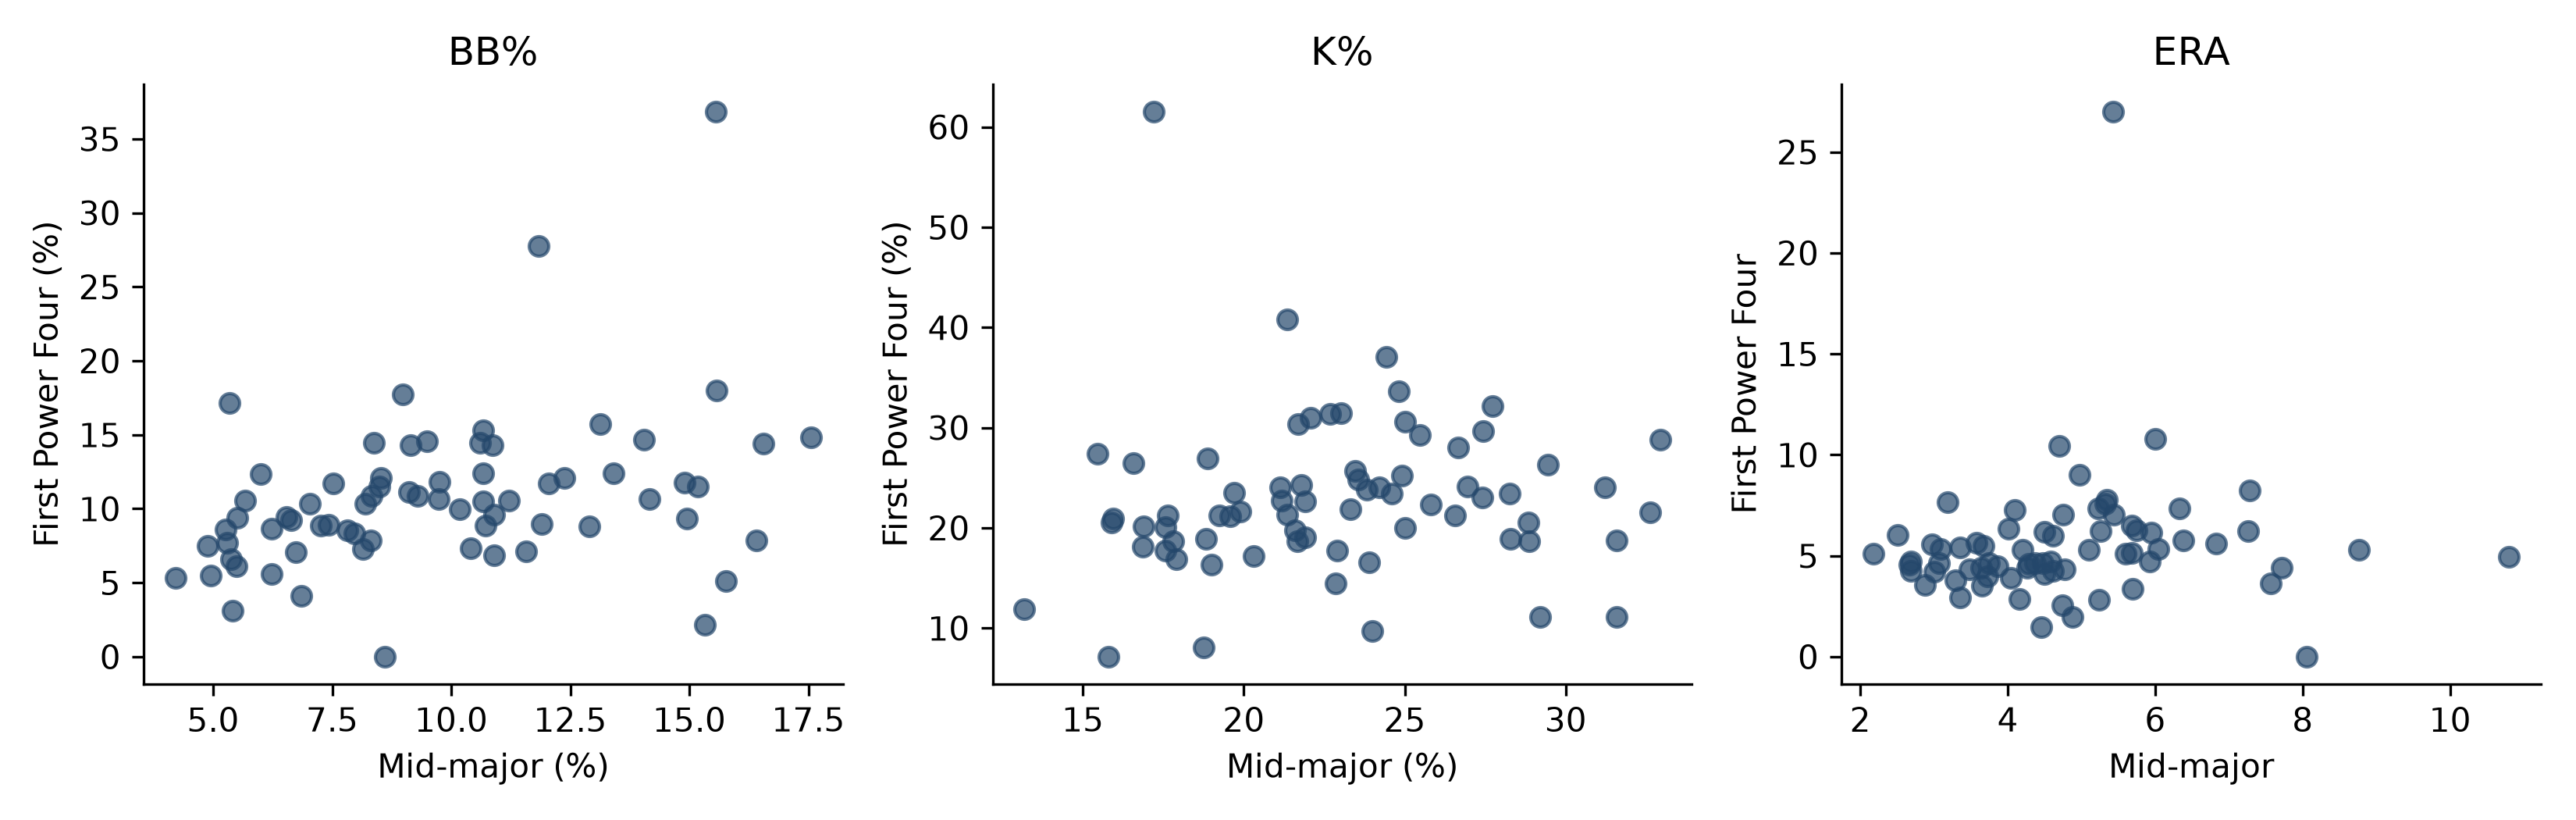

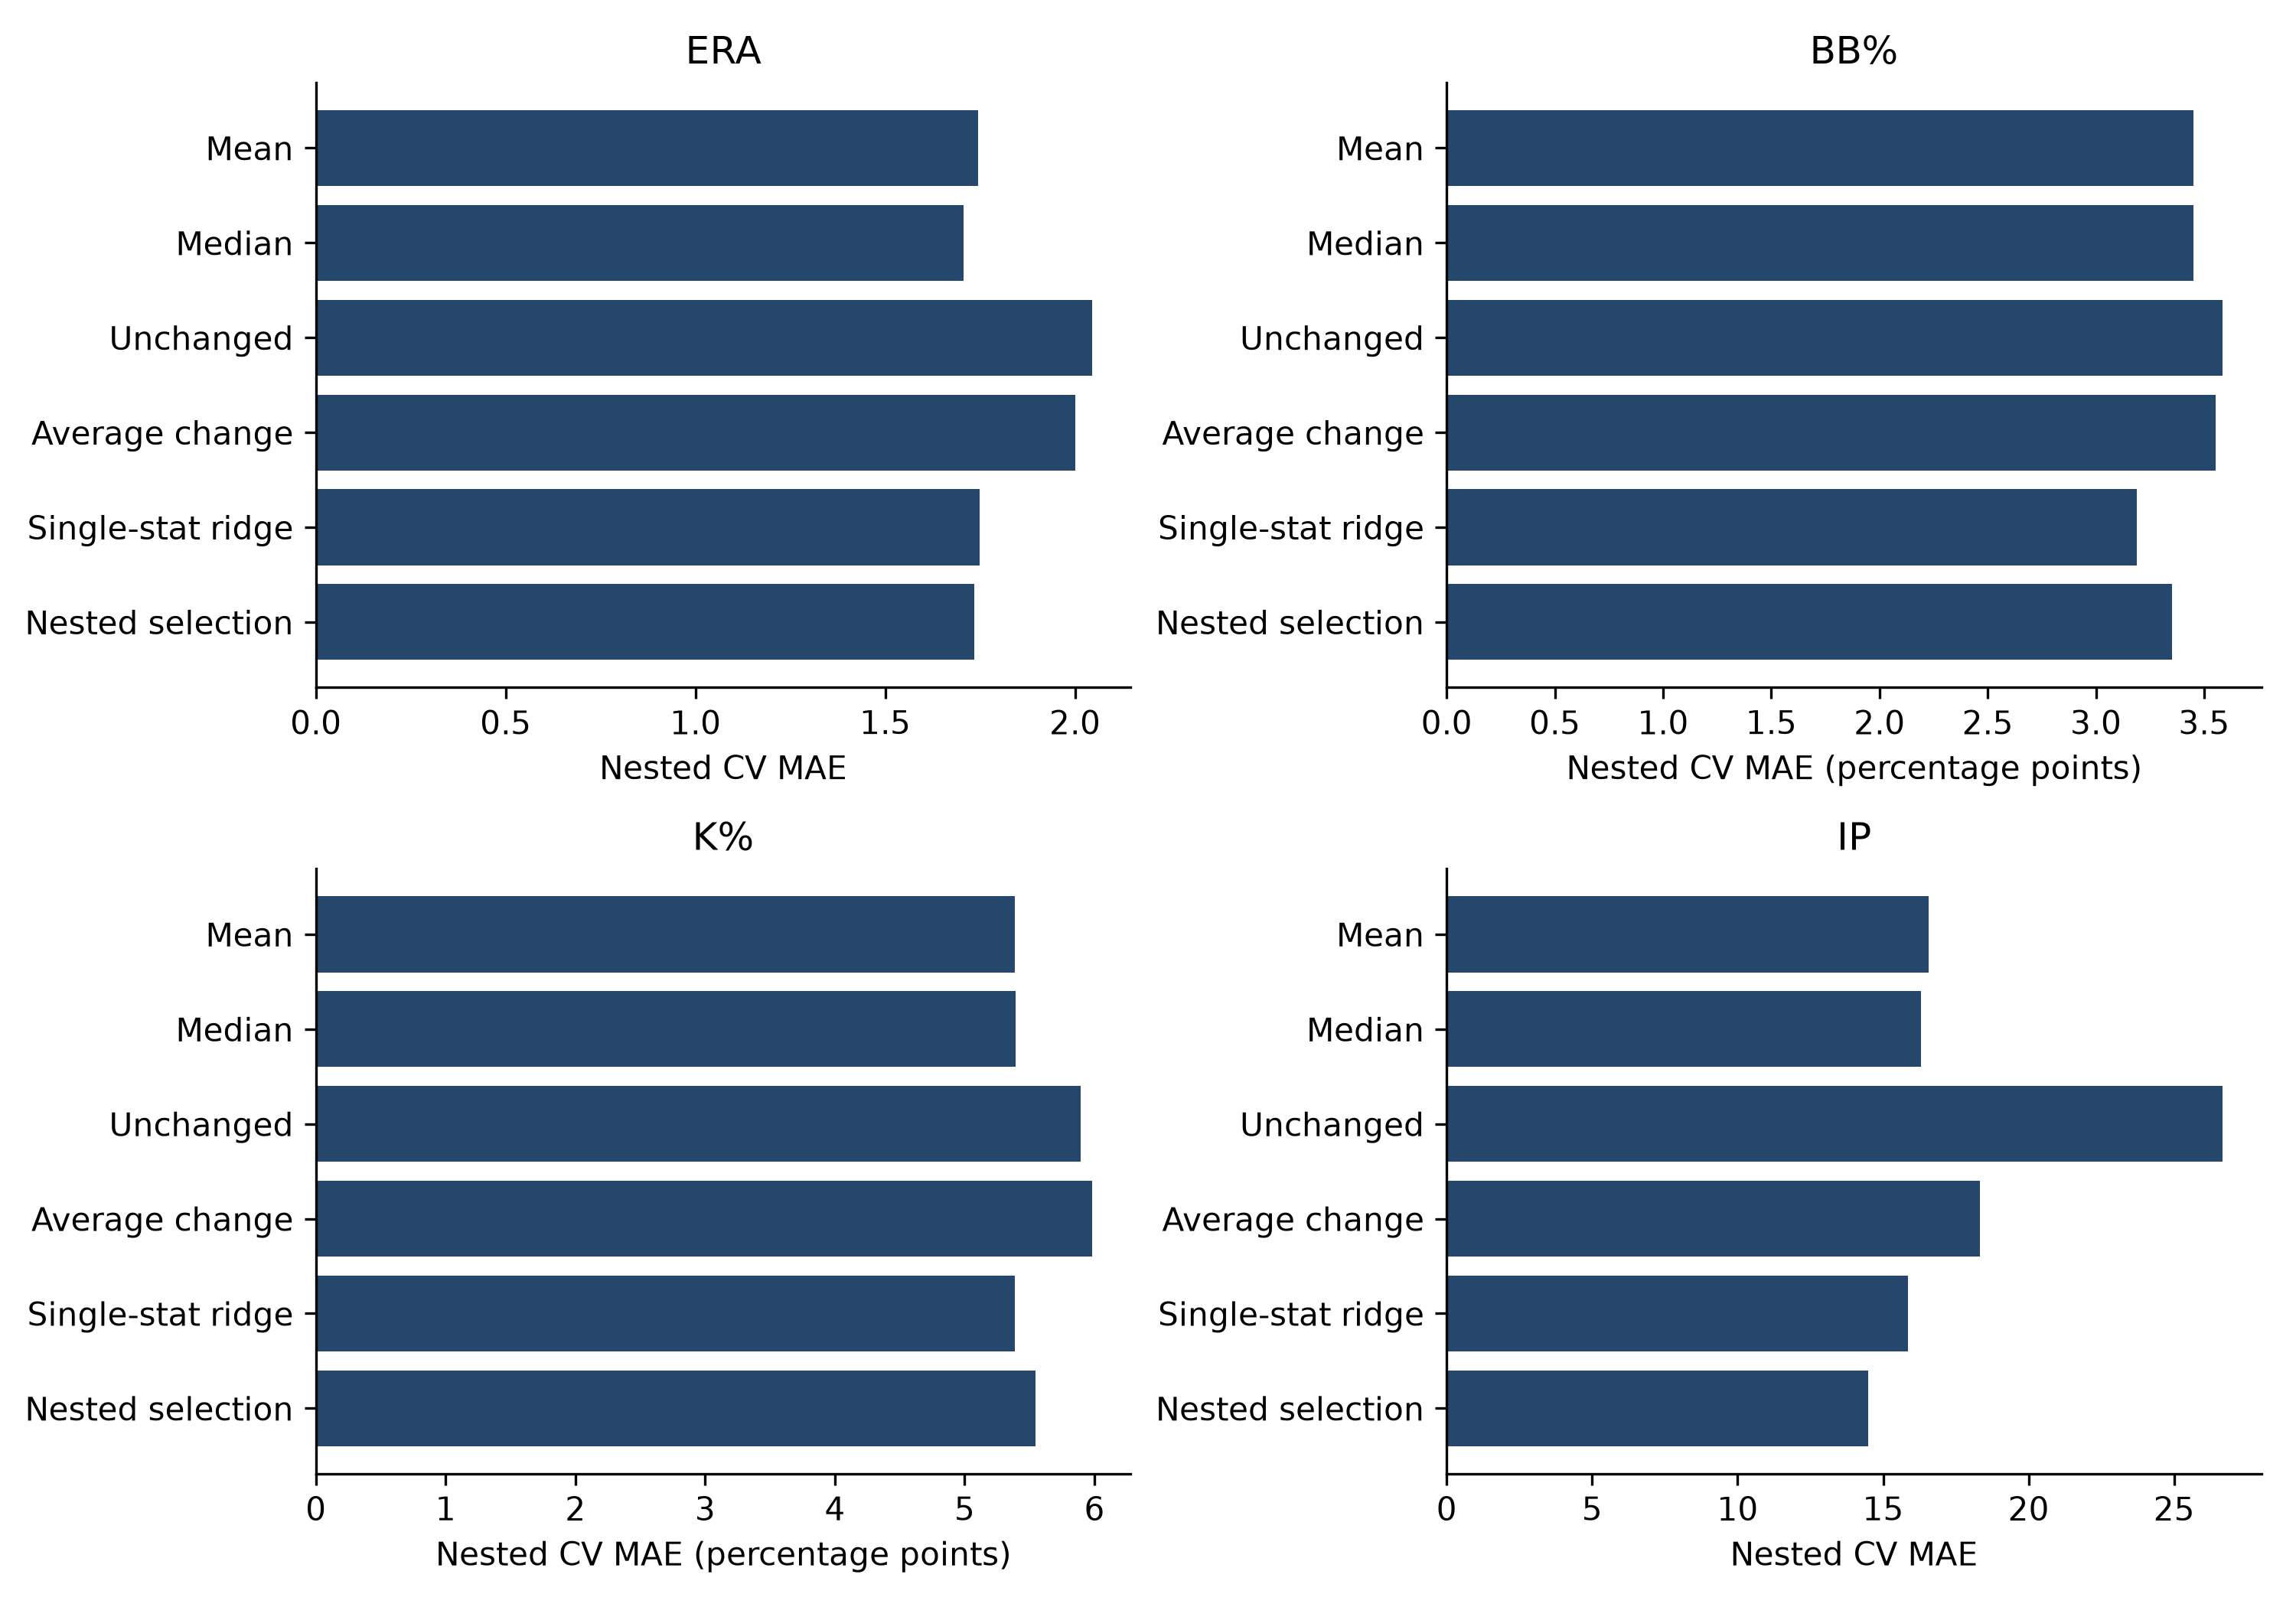

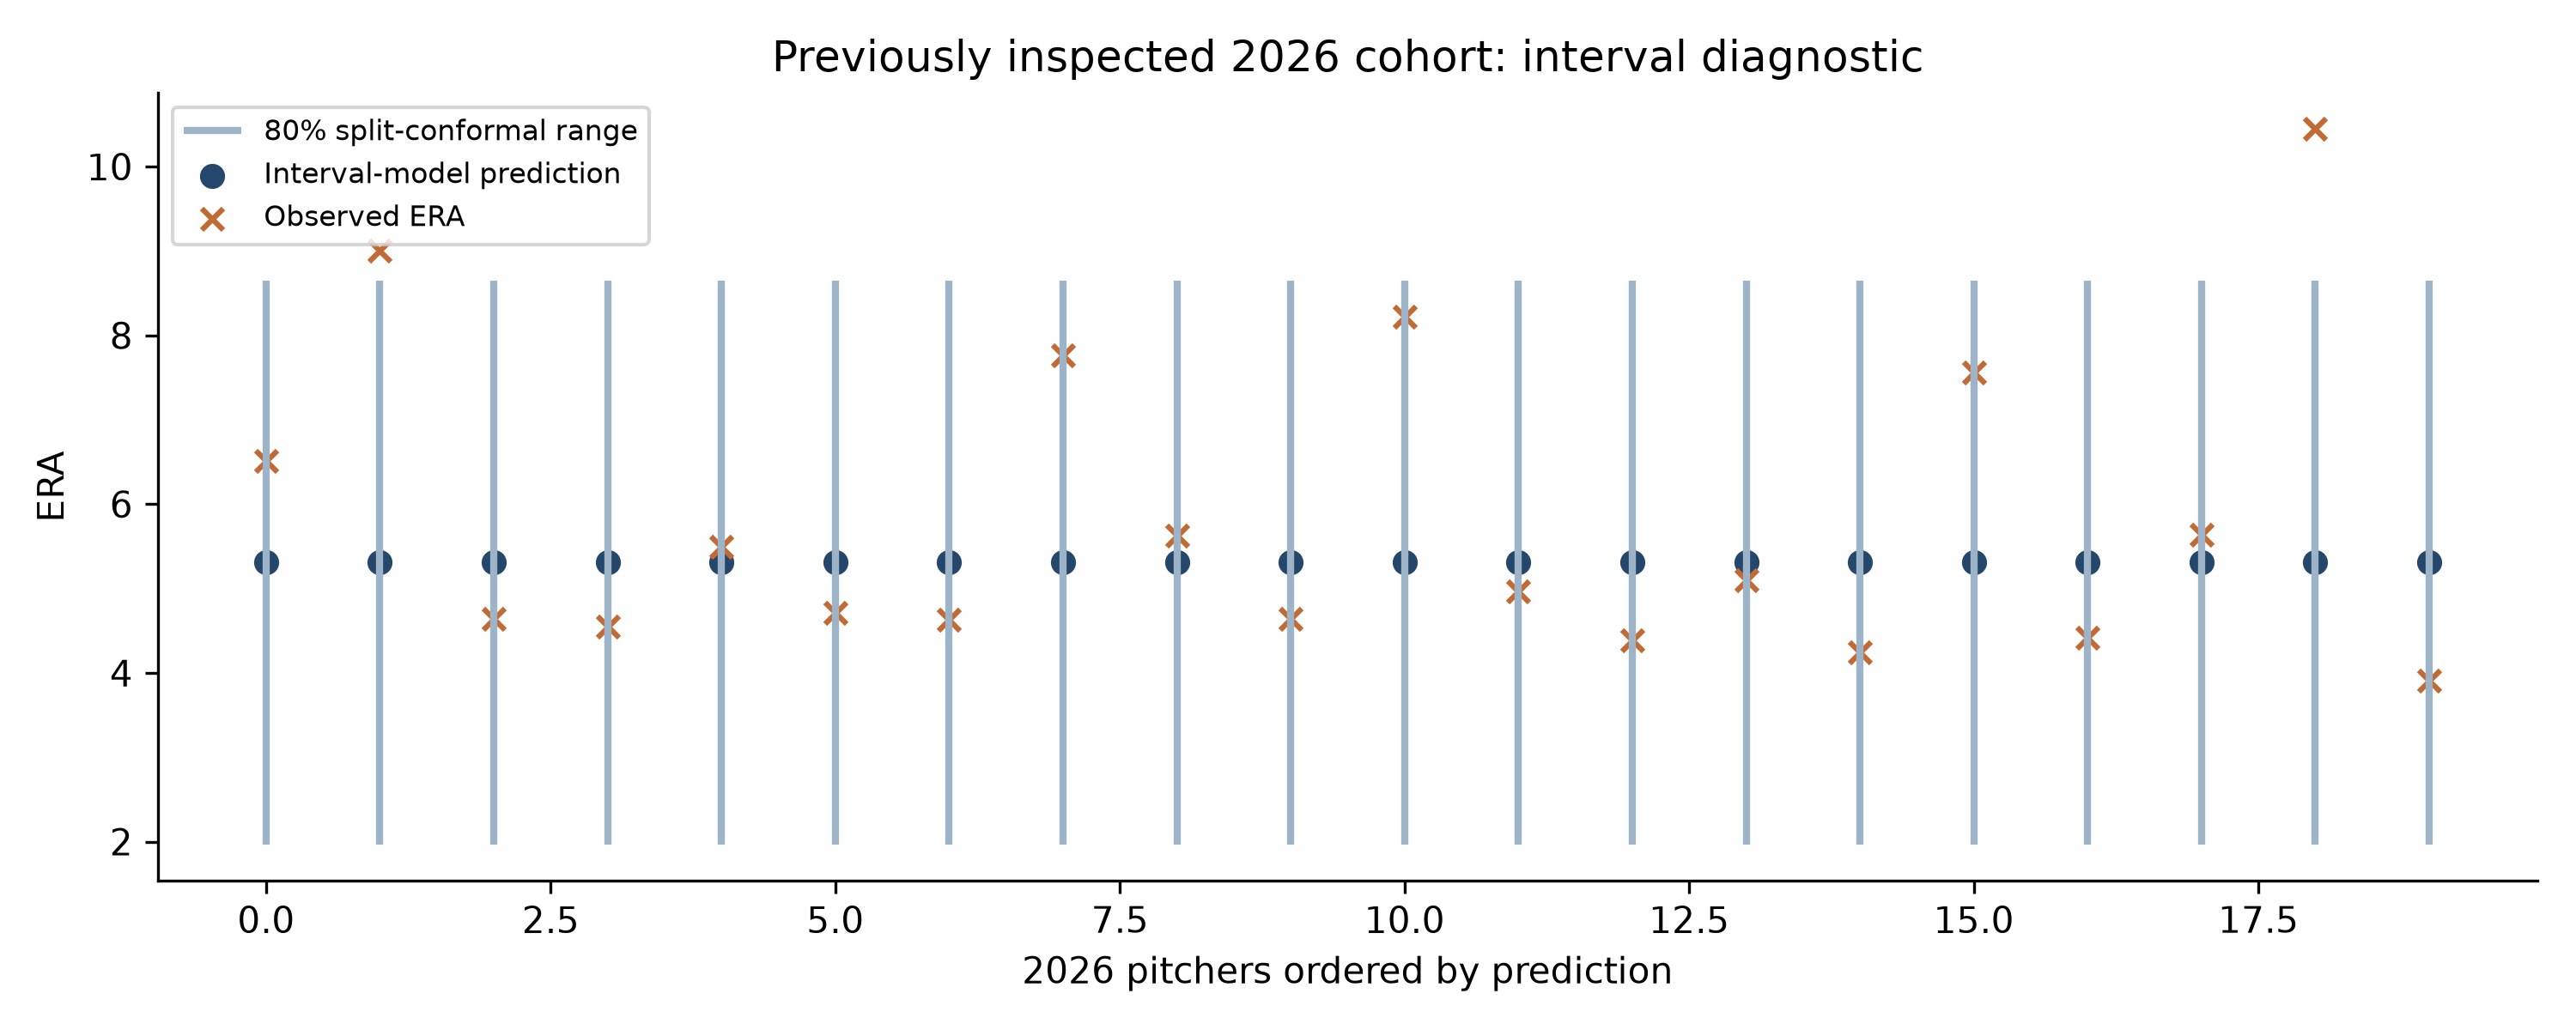

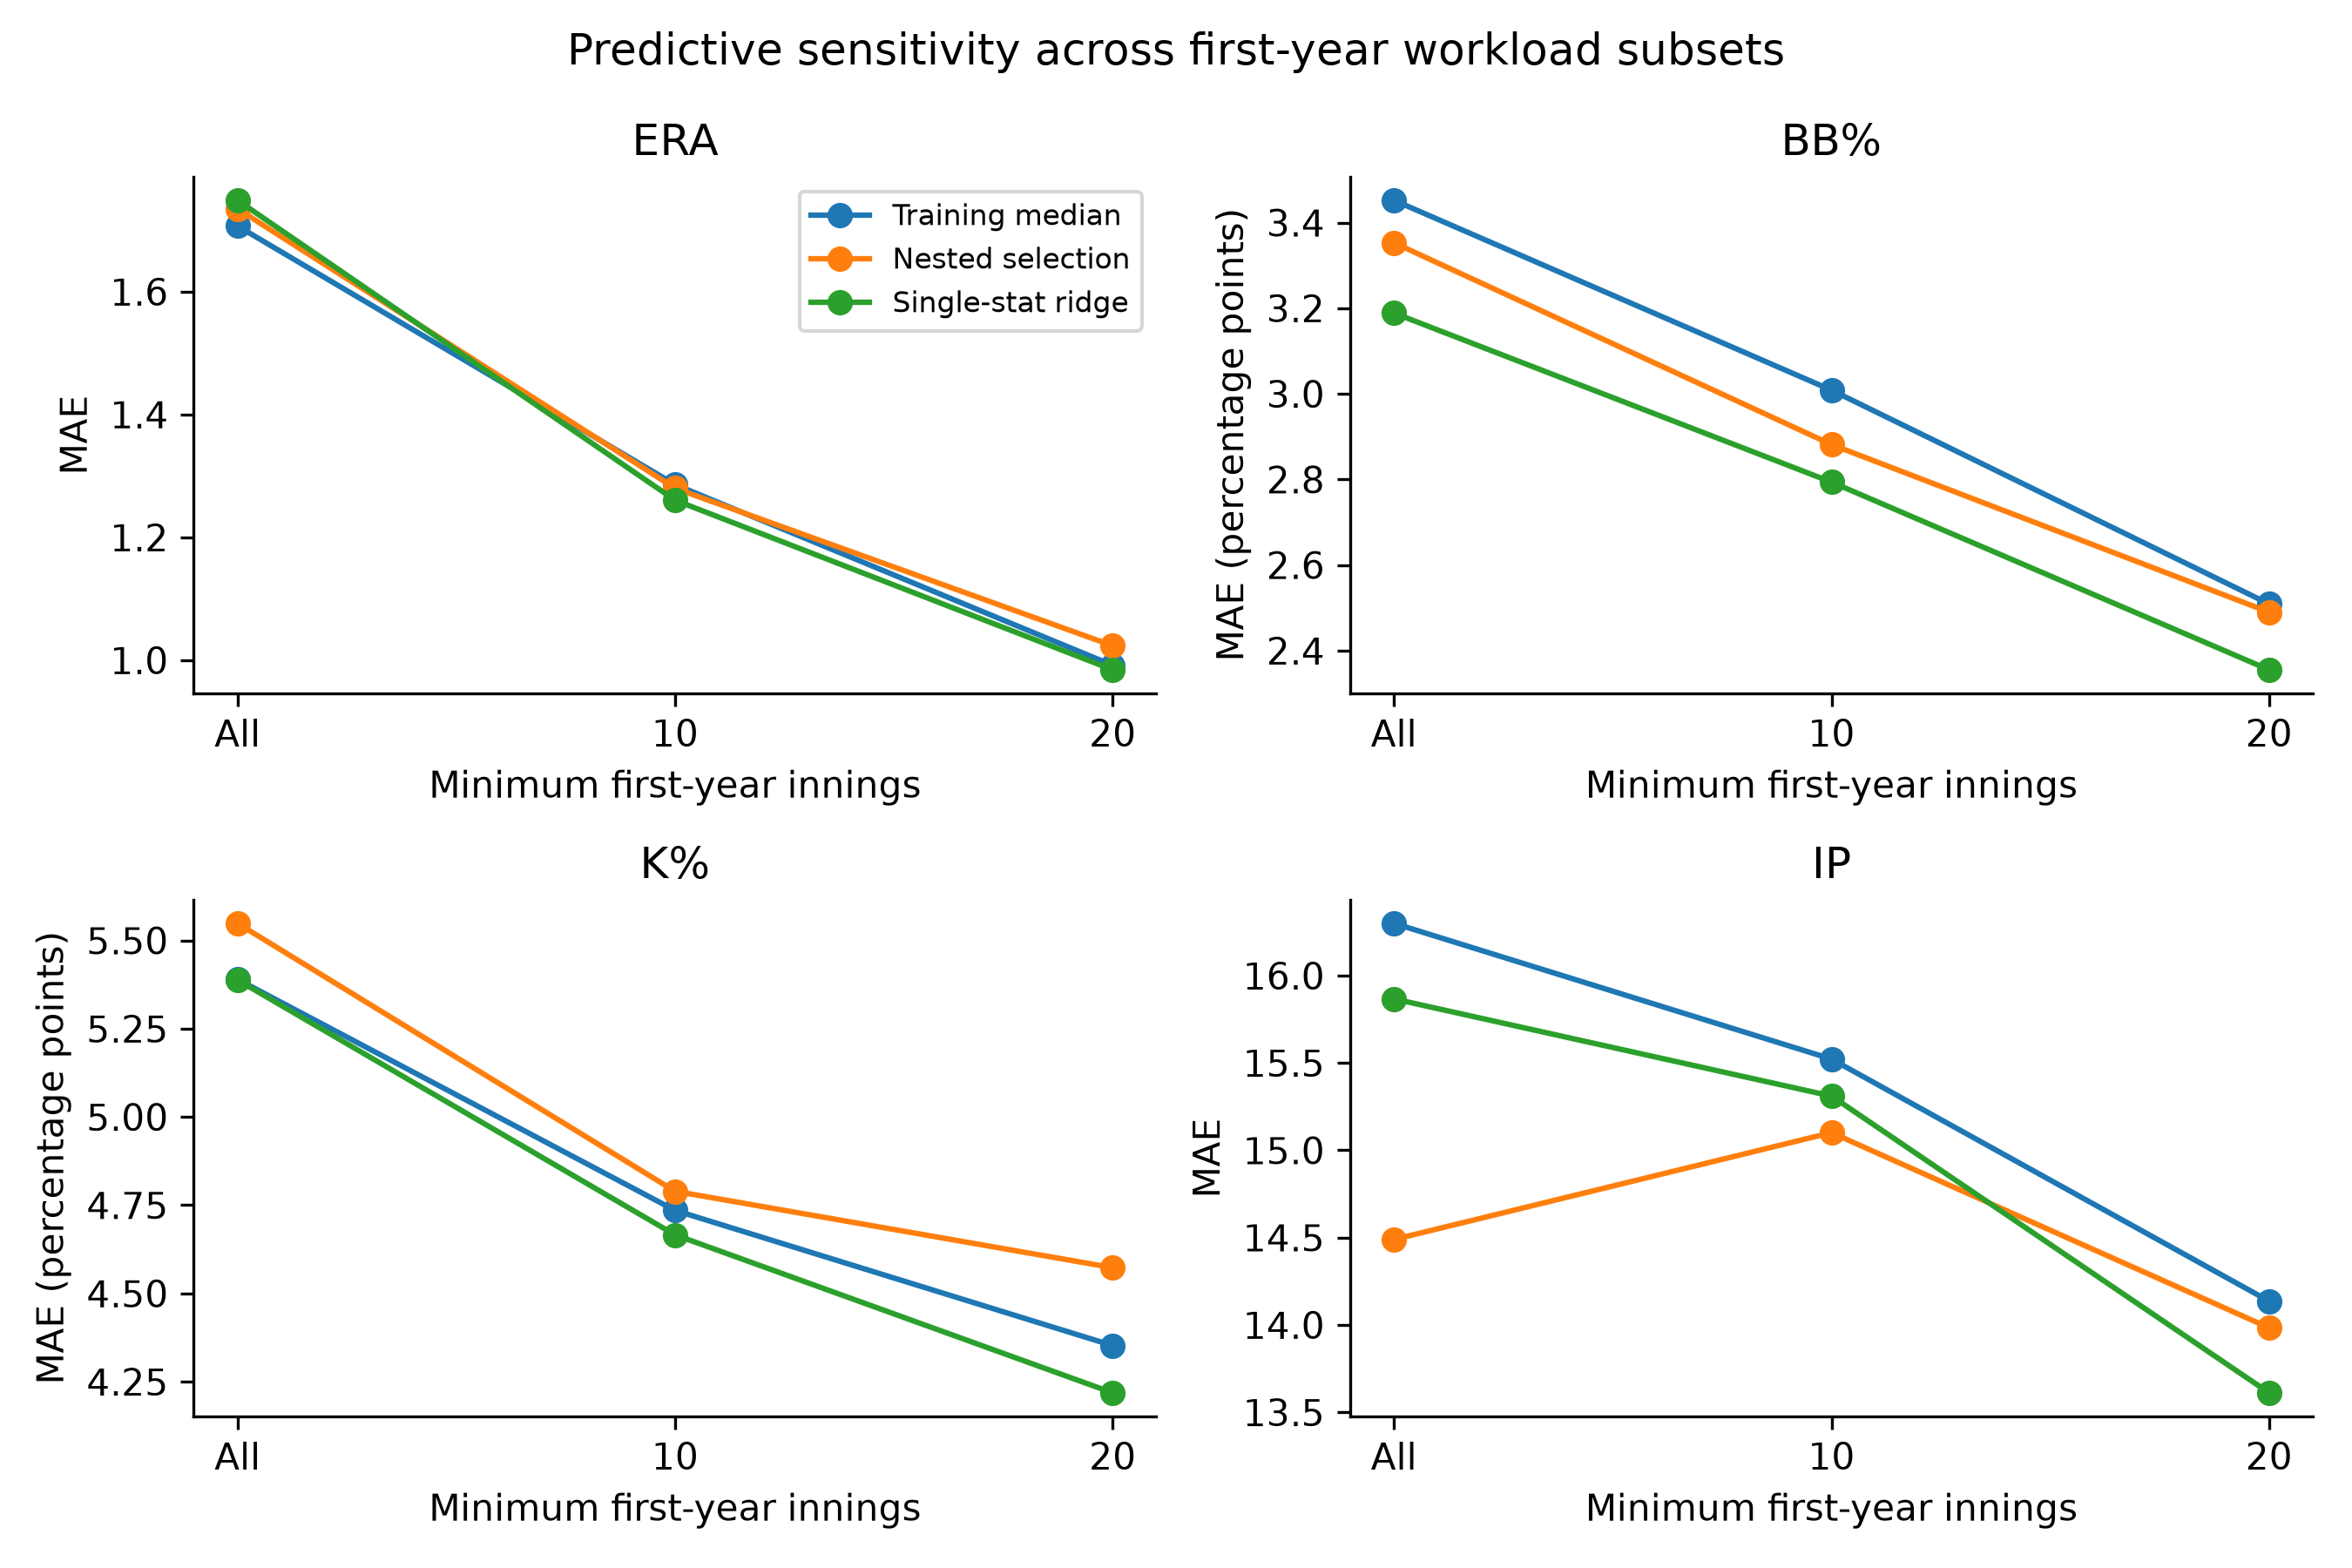

In [11]:
from IPython.display import display, Image, Markdown
display(Markdown((OUT / 'paper_findings.md').read_text()))
display(results['nested_metrics'].query('target in @PRIMARY').round(4))
display(results['chronological_metrics'].query('target in @PRIMARY').round(4))
display(results['coverage'].round(3))
display(results['workload_feature_gains'].round(3))
display(results['predictive_sensitivity'].query("model in ['median', 'selected']").round(4))
display(results['selection_stability'].query('target in @PRIMARY and folds > 0'))
display(results['repeat_stability'].query("target in @PRIMARY and model in ['median', 'selected']").round(4))
for filename in sorted(OUT.glob('figure_*.png')):
    display(Image(filename=str(filename)))

## Project a new pitcher
Use `results_final/new_pitcher_input_template.csv`. Enter rates as proportions and innings as true decimal innings (`56.1` baseball innings becomes `56 + 1/3`). The historical sample is selected and predictions may not generalize to all recruits. The separately calibrated interval center can differ from the all-data point prediction. The model is not a causal estimate or NIL valuation.

In [12]:
# candidates = pd.read_csv('my_candidates.csv')
# projected = project_pitchers(candidates, results['bundle'])
# projected.to_csv(OUT / 'candidate_projections.csv', index=False)